In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
#梯度 = 导数
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,GradientBoostingClassifier,GradientBoostingRegressor
from sklearn import datasets

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder

from sklearn import tree

In [11]:
X,y = datasets.load_iris(return_X_y=True)
# cond = y!=2
# X = X[cond]
# y = y[cond]


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

In [13]:
gbdt = GradientBoostingClassifier(n_estimators=10)
gbdt.fit(X_train,y_train)
gbdt.score(X_test,y_test)


1.0

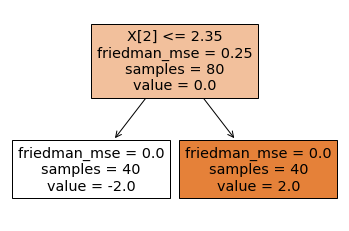

In [15]:
gbdt.estimators_.shape
_ = tree.plot_tree(gbdt.estimators_[0][0],filled=True)

In [ ]:
#使用非数值类型 进行决策树分析

In [10]:
data = pd.read_csv('../datas/adult.data',names=['age','workclass','final_weight','education','education-num','marital-status',
                                              'occupation','relationship','race','sex','capital-gain','capital-loss',
                                               'hours-per-week','native-country','salary'])
data.drop(labels=['final_weight','education','capital-gain','capital-loss'],axis=1,inplace=True)
X = data.iloc[:,0:-1]
y = data['salary']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)
X1 = X.loc[:,['workclass','marital-status',
    'occupation','relationship','race','sex',
    'native-country']]
X2 = X.loc[:,['age','education-num','hours-per-week']]


In [24]:
ordinalEncoder = OrdinalEncoder()
X1 = ordinalEncoder.fit_transform(X1)
X1 = pd.DataFrame(X1,columns=['workclass', 'marital-status', 'occupation', 'relationship', 'race',
       'sex', 'native-country'])
X = pd.concat([X1,X2],axis=1)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

In [33]:

# gbdt = ExtraTreesClassifier(criterion='entropy') #'entropy'

gbdt = GradientBoostingClassifier(n_estimators=100)
gbdt.fit(X_train,y_train)

gbdt.score(X_test,y_test)

0.8350990327038231

In [34]:
y_ = gbdt.predict(X_test)
y_

array([1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1])

In [35]:
y_train

array([0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,